# Which Public Health Factors Have the Greatest Impact on Life Expectancy?

**Dataset:** WHO Global Health Observatory – Life Expectancy Data (193 countries, 2000–2015)

In this project I try to find out which factors affect life expectancy the most. I follow the 7 tasks given in the project brief.

In [1]:
# importing the libraries I need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

## Task 1: Read the data and feature engineering

In [2]:
df = pd.read_csv('Life_Expectancy_Data.csv')
print(df.shape)
df.head()

(2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


Some column names have extra spaces (like `'Life expectancy '` and `' BMI '`), so I clean them first.

In [3]:
df.columns = df.columns.str.strip().str.replace(r'\s+', ' ', regex=True)
print(df.columns.tolist())

['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness 1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2.007519e+03,4.613841e+00,2000.00000,2004.000000,2.008000e+03,2.012000e+03,2.015000e+03
Life expectancy,2928.0,6.922493e+01,9.523867e+00,36.30000,63.100000,7.210000e+01,7.570000e+01,8.900000e+01
Adult Mortality,2928.0,1.647964e+02,1.242921e+02,1.00000,74.000000,1.440000e+02,2.280000e+02,7.230000e+02
infant deaths,2938.0,3.030395e+01,1.179265e+02,0.00000,0.000000,3.000000e+00,2.200000e+01,1.800000e+03
Alcohol,2744.0,4.602861e+00,4.052413e+00,0.01000,0.877500,3.755000e+00,7.702500e+00,1.787000e+01
percentage expenditure,2938.0,7.382513e+02,1.987915e+03,0.00000,4.685343,6.491291e+01,4.415341e+02,1.947991e+04
Hepatitis B,2385.0,8.094046e+01,2.507002e+01,1.00000,77.000000,9.200000e+01,9.700000e+01,9.900000e+01
Measles,2938.0,2.419592e+03,1.146727e+04,0.00000,0.000000,1.700000e+01,3.602500e+02,2.121830e+05
BMI,2904.0,3.832125e+01,2.004403e+01,1.00000,19.300000,4.350000e+01,5.620000e+01,8.730000e+01
under-five deaths,2938.0,4.203574e+01,1.604455e+02,0.00000,0.000000,4.000000e+00,2.800000e+01,2.500000e+03


### Creating the new features

1. **Population Size** – Small (1,000–29,999), Medium (30,000–99,999), Large (100,000+).
   A few rows have population under 1,000 (31 rows). The brief doesn't give a category for them, so I put them in *Small* because they are clearly small populations.
2. **Lifestyle** – Alcohol × BMI (combines drinking and body mass)
3. **Economy** – GDP × Population (GDP is per person, so multiplying by population gives roughly the total size of the economy)
4. **Death Ratio** – Adult Mortality / Infant deaths. Many countries have 0 infant deaths, which would give division by zero, so I add 1 to the bottom: `Adult Mortality / (infant deaths + 1)`.

I put this in a function because I need to run it again after filling the missing values in Task 2.

In [6]:
def add_features(data):
    data['Population Size'] = pd.cut(data['Population'],
                                     bins=[0, 30000, 100000, np.inf],
                                     labels=['Small', 'Medium', 'Large'],
                                     right=False)
    data['Lifestyle'] = data['Alcohol'] * data['BMI']
    data['Economy'] = data['GDP'] * data['Population']
    data['Death Ratio'] = data['Adult Mortality'] / (data['infant deaths'] + 1)
    return data

df = add_features(df)
df[['Country', 'Year', 'Population', 'Population Size', 'Lifestyle', 'Economy', 'Death Ratio']].head(10)

,Country,Year,Population,Population Size,Lifestyle,Economy,Death Ratio
0,Afghanistan,2015,33736494.0,Large,0.191,1.971086e+10,4.174603
1,Afghanistan,2014,327582.0,Large,0.186,2.007083e+08,4.169231
2,Afghanistan,2013,31731688.0,Large,0.181,2.004633e+10,4.000000
3,Afghanistan,2012,3696958.0,Large,0.176,2.476810e+09,3.885714
4,Afghanistan,2011,2978599.0,Large,0.172,1.892519e+08,3.819444
5,Afghanistan,2010,2883167.0,Large,0.167,1.595340e+09,3.720000
6,Afghanistan,2009,284331.0,Large,0.162,1.267813e+08,3.602564
7,Afghanistan,2008,2729431.0,Large,0.471,1.019063e+09,3.543210
8,Afghanistan,2007,26616792.0,Large,0.304,9.843842e+09,3.554217
9,Afghanistan,2006,2589345.0,Large,0.441,7.057616e+08,3.470588


In [7]:
df['Population Size'].value_counts()

Population Size
Large     1874
Small      236
Medium     176
Name: count, dtype: int64

## Task 2: Data cleaning, scatter plots and transformations

In [8]:
# missing values in each column
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

Economy                            674
Population                         652
Population Size                    652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Lifestyle                          211
Alcohol                            194
Income composition of resources    167
Schooling                          163
BMI                                 34
thinness 1-19 years                 34
thinness 5-9 years                  34
Polio                               19
Diphtheria                          19
Life expectancy                     10
Adult Mortality                     10
Death Ratio                         10
dtype: int64

**Steps I follow for cleaning:**
- Remove the 10 rows where *Life expectancy* (the target) is missing. These are small countries with only one year of data, so I can't fill them.
- *Schooling* and *Income composition of resources* have some 0 values, which are not realistic (a country can't have 0 years of schooling), so I treat them as missing.
- Fill missing values with the **median of the same country** first (a country's values don't change much year to year). If a country has no values at all for a column, I use the overall median.

In [9]:
df = df.dropna(subset=['Life expectancy'])

df.loc[df['Schooling'] == 0, 'Schooling'] = np.nan
df.loc[df['Income composition of resources'] == 0, 'Income composition of resources'] = np.nan

base_cols = ['Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
             'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria',
             'HIV/AIDS', 'GDP', 'Population', 'thinness 1-19 years', 'thinness 5-9 years',
             'Income composition of resources', 'Schooling']

for col in base_cols:
    df[col] = df[col].fillna(df.groupby('Country')[col].transform('median'))  # country median
    df[col] = df[col].fillna(df[col].median())                                 # overall median

# re-create the engineered features now that there are no gaps
df = add_features(df)
print('Missing values left:', df.isnull().sum().sum())
print(df.shape)

Missing values left: 0
(2928, 26)


### Scatter plots: each predictor vs Life expectancy

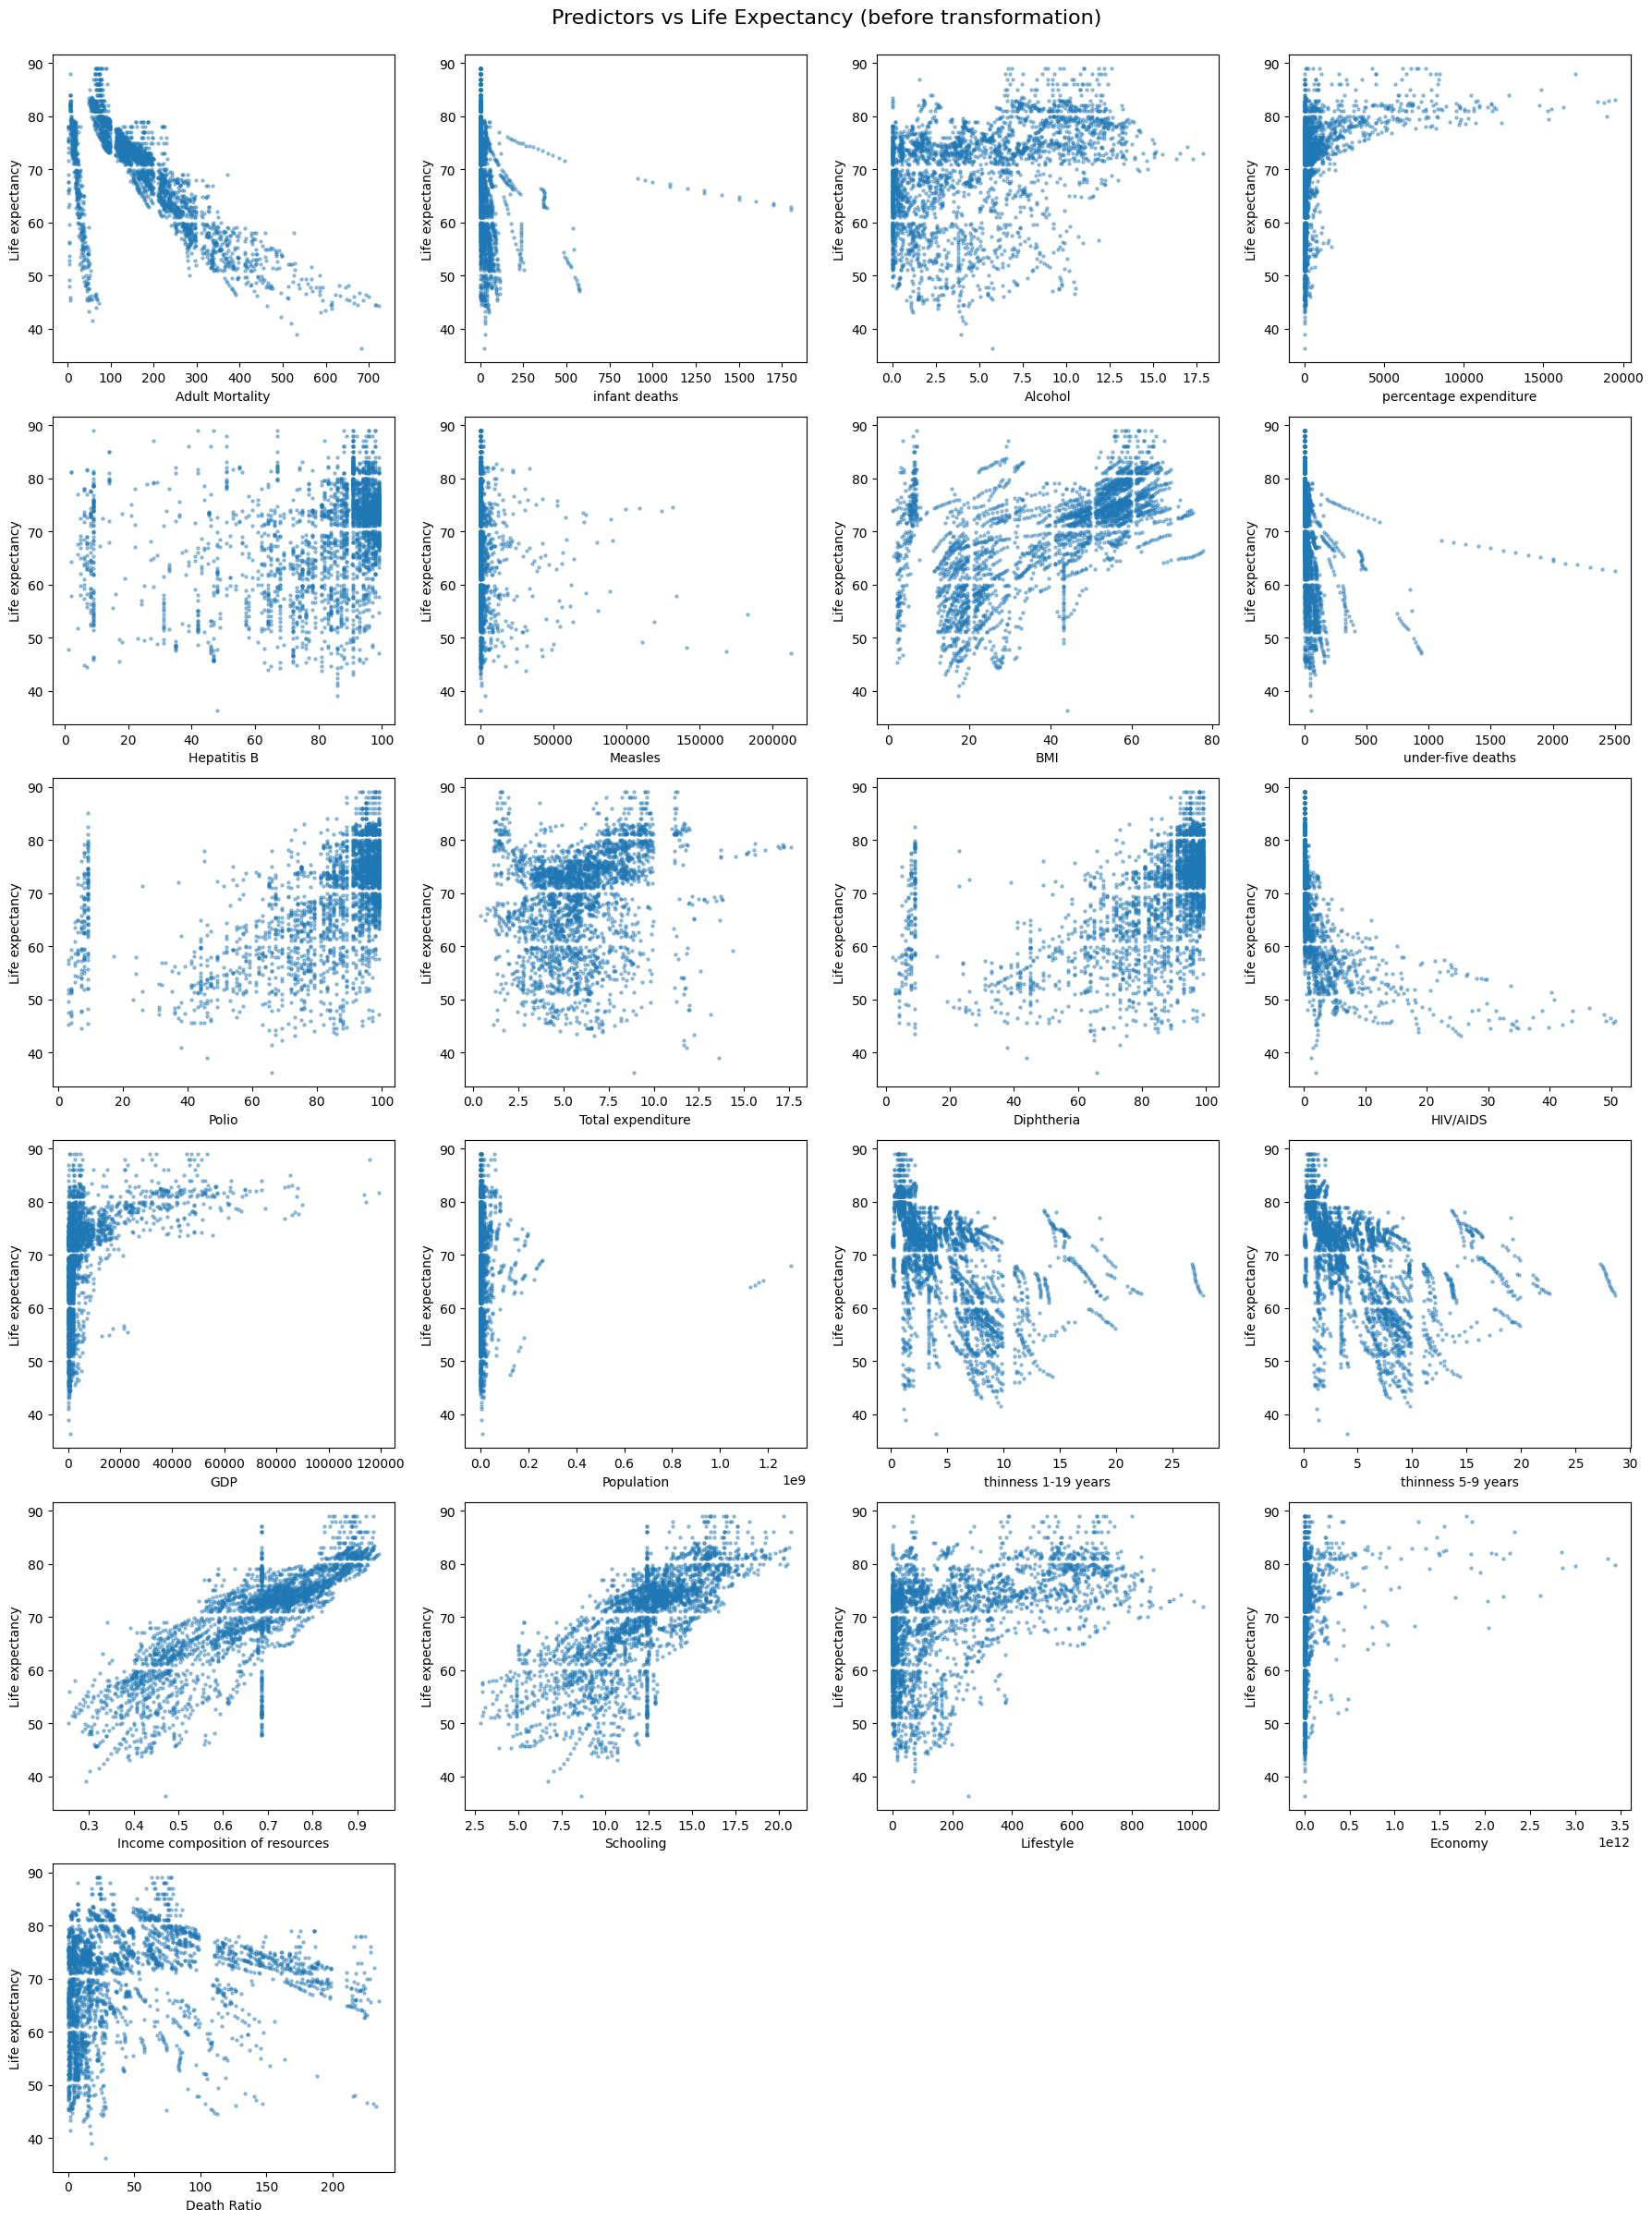

In [10]:
target = 'Life expectancy'
predictors = base_cols + ['Lifestyle', 'Economy', 'Death Ratio']

fig, axes = plt.subplots(6, 4, figsize=(18, 24))
axes = axes.flatten()
for i, col in enumerate(predictors):
    axes[i].scatter(df[col], df[target], s=5, alpha=0.4)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel(target)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.suptitle('Predictors vs Life Expectancy (before transformation)', y=1.0, fontsize=16)
plt.tight_layout()
plt.show()

**Observation:** Adult Mortality, Income composition, Schooling and BMI show a fairly clear linear trend. But columns like GDP, Population, Measles, HIV/AIDS, infant deaths and under-five deaths are very squeezed to the left with a few huge values, so the relationship is not linear. I check the skewness to decide which ones need a log transform.

In [11]:
skewness = df[predictors].skew().sort_values(ascending=False)
skewness

Population                         17.943504
infant deaths                       9.771044
under-five deaths                   9.479623
Measles                             9.425290
Economy                             8.671340
HIV/AIDS                            5.386623
percentage expenditure              4.643790
GDP                                 3.534664
thinness 5-9 years                  1.793650
thinness 1-19 years                 1.727662
Death Ratio                         1.372769
Adult Mortality                     1.174369
Lifestyle                           1.109596
Alcohol                             0.589119
Total expenditure                   0.587661
BMI                                -0.239842
Schooling                          -0.331243
Income composition of resources    -0.387456
Hepatitis B                        -1.830203
Diphtheria                         -2.047104
Polio                              -2.070627
dtype: float64

I apply a **log transform** (`np.log1p`, which works with 0 values) to every column with skewness above 2.

Log transformed columns: ['Population', 'infant deaths', 'under-five deaths', 'Measles', 'Economy', 'HIV/AIDS', 'percentage expenditure', 'GDP']


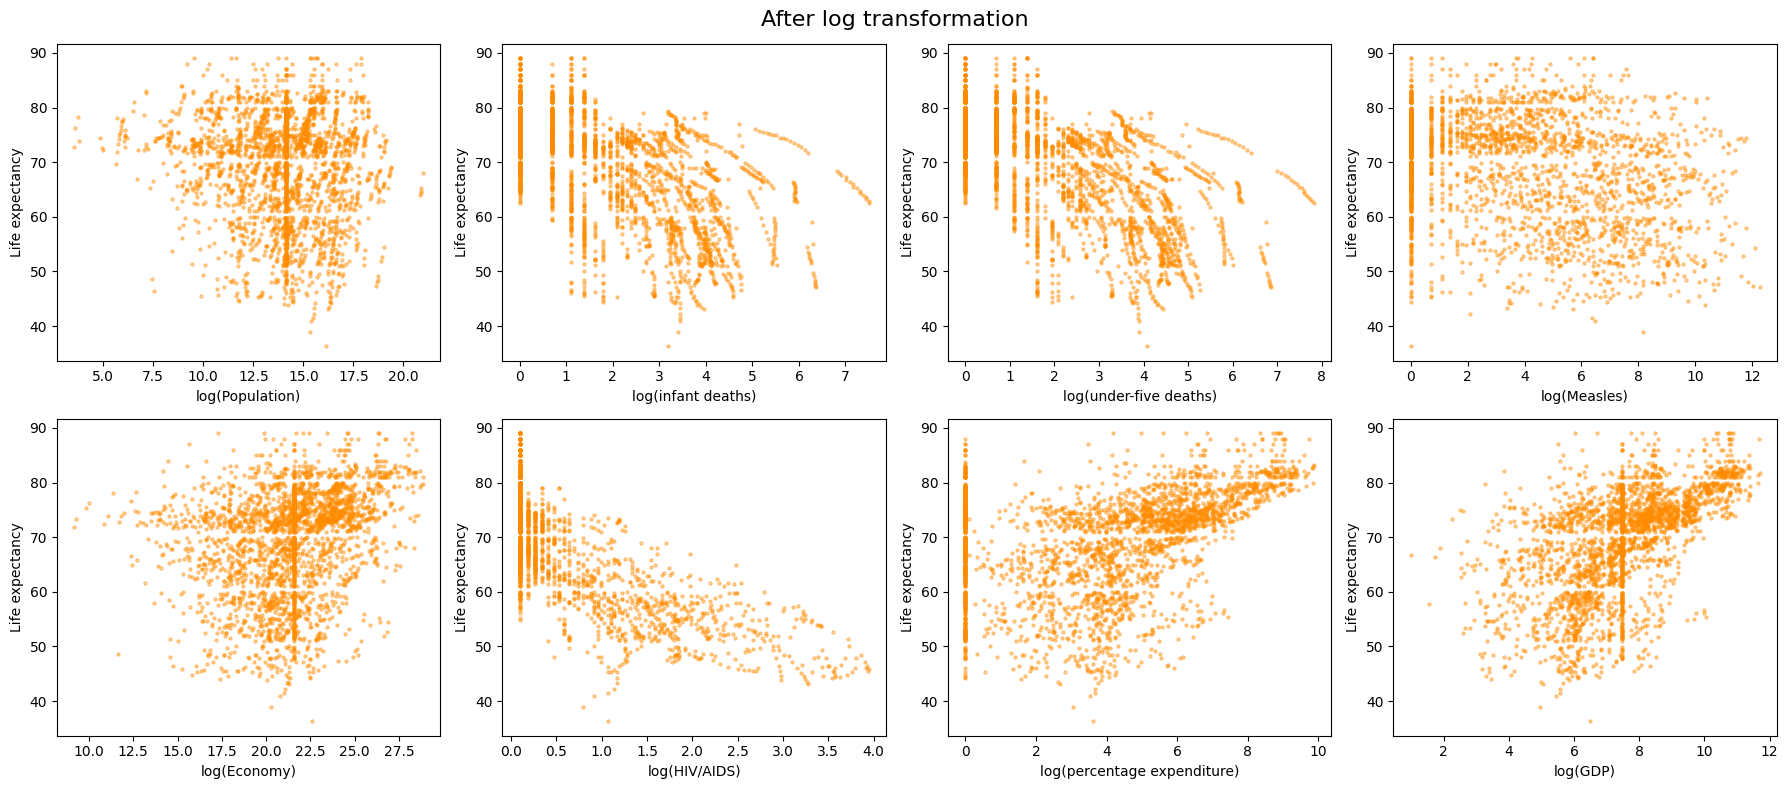

In [12]:
log_cols = skewness[skewness > 2].index.tolist()
print('Log transformed columns:', log_cols)

for col in log_cols:
    df[col] = np.log1p(df[col])

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(log_cols):
    axes[i].scatter(df[col], df[target], s=5, alpha=0.4, color='darkorange')
    axes[i].set_xlabel('log(' + col + ')')
    axes[i].set_ylabel(target)
plt.suptitle('After log transformation', fontsize=16)
plt.tight_layout()
plt.show()

**Observation:** After the log transform, the points are spread out much better and the trends (for example GDP and HIV/AIDS) look a lot more linear.

One thing I noticed: there are **vertical lines of points** in some plots (log(Population) around 14, log(GDP) around 7.5, Schooling at 12.5, Income composition around 0.69). These come from my imputation. Some countries had *no* values at all for that column, so they all got the same overall median. This is a limitation of median imputation, but it only affects a small number of countries.

## Task 3: Correlation heat map (multicollinearity, threshold 0.75)

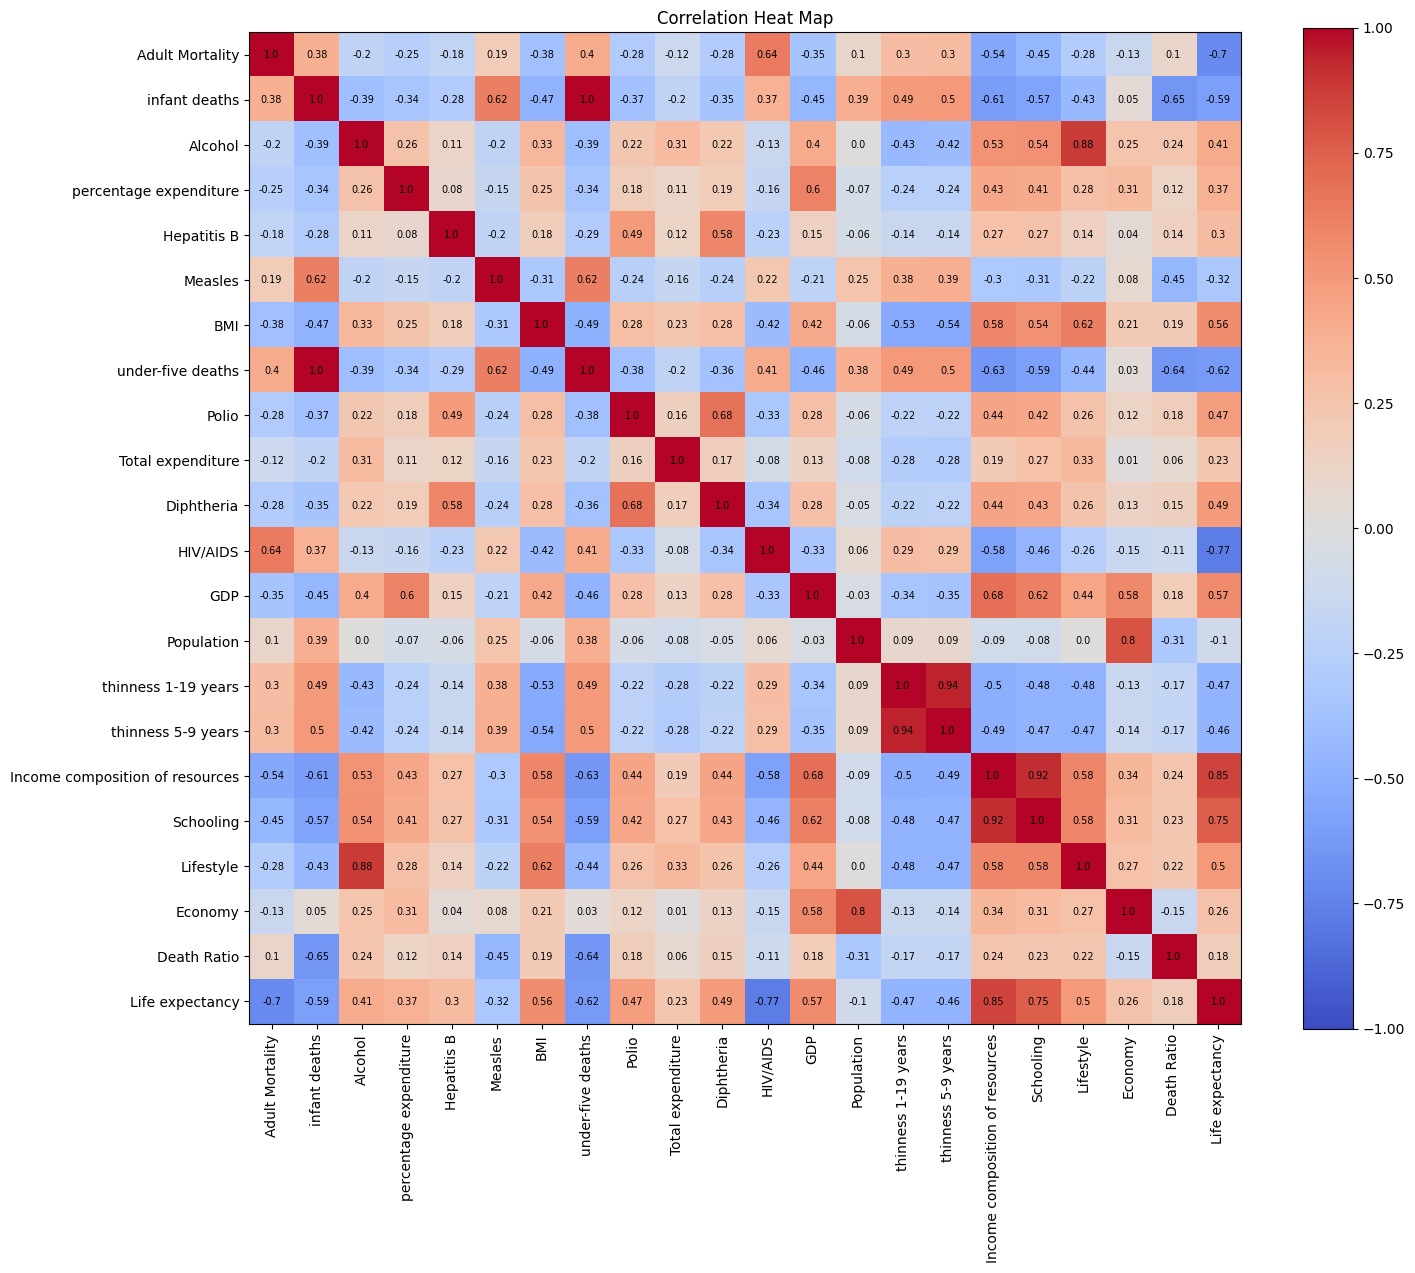

In [13]:
corr = df[predictors + [target]].corr()

fig, ax = plt.subplots(figsize=(16, 13))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=7)
plt.colorbar(im)
plt.title('Correlation Heat Map')
plt.show()

Now I find every pair of predictors with |correlation| > 0.75. For each pair I drop the one that is **less correlated with life expectancy**, so I keep the more useful one.

In [14]:
target_corr = df[predictors].corrwith(df[target]).abs()
to_drop = []

for i in range(len(predictors)):
    for j in range(i + 1, len(predictors)):
        a, b = predictors[i], predictors[j]
        if a in to_drop or b in to_drop:
            continue
        if abs(corr.loc[a, b]) > 0.75:
            drop = a if target_corr[a] < target_corr[b] else b
            to_drop.append(drop)
            print(f'{a} & {b}: r = {corr.loc[a, b]:.2f}  -> drop {drop}')

features = [c for c in predictors if c not in to_drop]
print('\nDropped:', to_drop)
print('Remaining features:', len(features))

infant deaths & under-five deaths: r = 1.00  -> drop infant deaths
Alcohol & Lifestyle: r = 0.88  -> drop Alcohol
Population & Economy: r = 0.80  -> drop Population
thinness 1-19 years & thinness 5-9 years: r = 0.94  -> drop thinness 5-9 years
Income composition of resources & Schooling: r = 0.92  -> drop Schooling

Dropped: ['infant deaths', 'Alcohol', 'Population', 'thinness 5-9 years', 'Schooling']
Remaining features: 16


**Observation:** infant deaths and under-five deaths are almost the same thing (r ≈ 1). Alcohol is mostly captured by my Lifestyle feature, Population by Economy, and the two thinness columns measure nearly the same thing. Schooling and Income composition are very highly correlated (0.92). I drop Schooling from the **model**, but I still use it in Task 5 to answer the schooling question.

## Task 4: Outliers – box-whisker plots

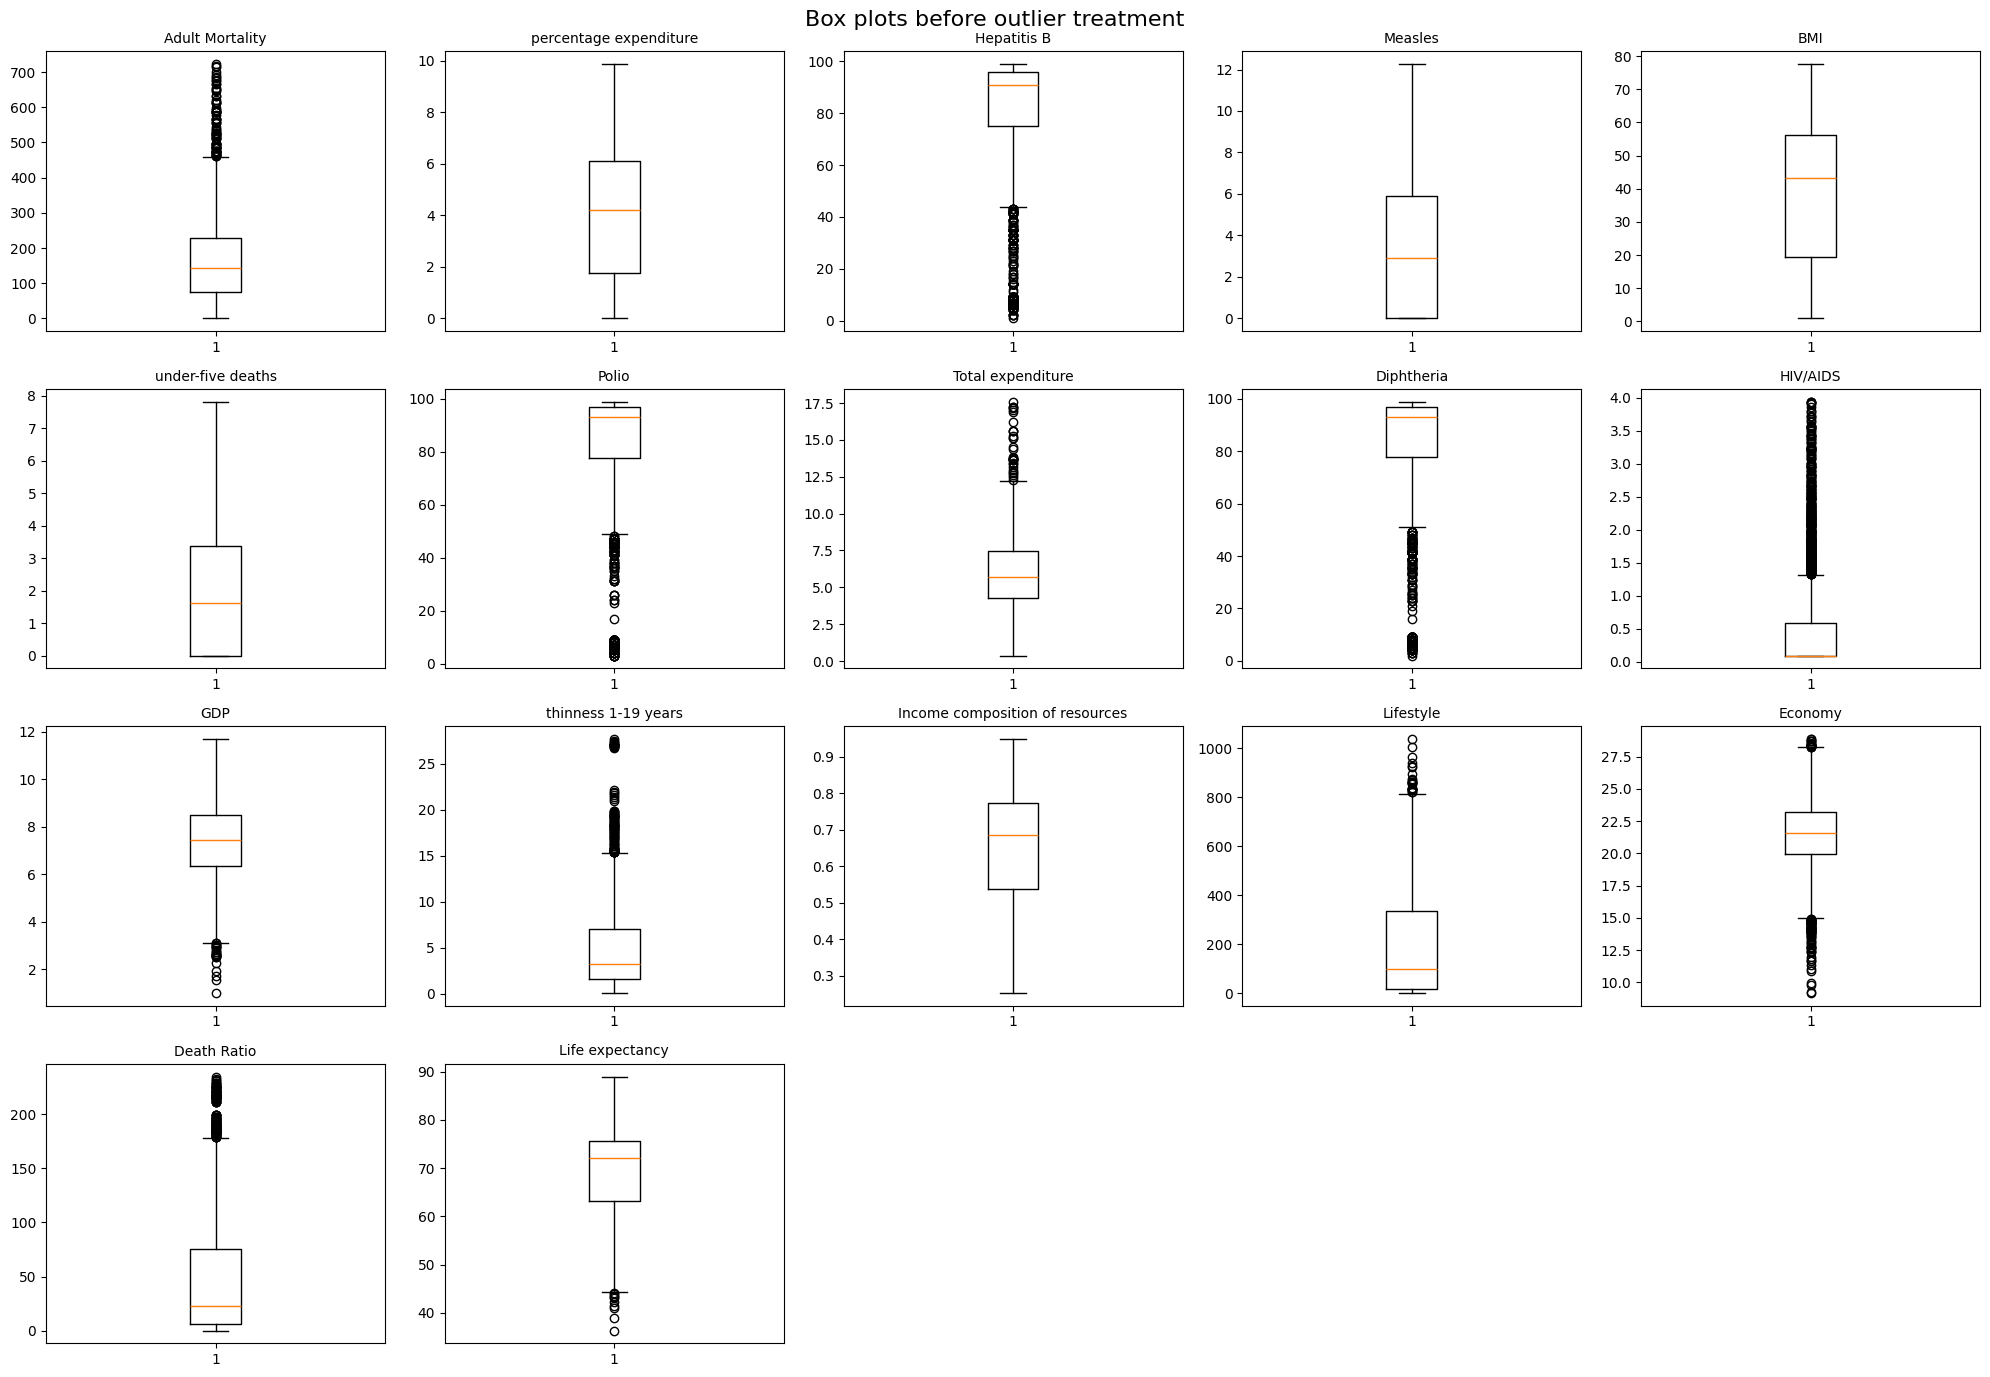

In [15]:
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
axes = axes.flatten()
for i, col in enumerate(features + [target]):
    axes[i].boxplot(df[col])
    axes[i].set_title(col, fontsize=10)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.suptitle('Box plots before outlier treatment', fontsize=16)
plt.tight_layout()
plt.show()

In [16]:
# count outliers using the IQR rule (1.5 * IQR)
Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = ((df[features] < lower) | (df[features] > upper))
print(outliers.sum())
print('\nRows with at least one outlier:', outliers.any(axis=1).sum(), 'out of', len(df))

Adult Mortality                     82
percentage expenditure               0
Hepatitis B                        293
Measles                              0
BMI                                  0
under-five deaths                    0
Polio                              278
Total expenditure                   32
Diphtheria                         308
HIV/AIDS                           421
GDP                                 25
thinness 1-19 years                100
Income composition of resources      0
Lifestyle                           24
Economy                             93
Death Ratio                        141
dtype: int64

Rows with at least one outlier: 1090 out of 2928


If I deleted every row that has an outlier, I would lose more than a third of the data (and most of the countries with high HIV or low vaccination, which are real cases, not mistakes). So instead of deleting rows I **cap** the outliers at the whisker limits. This removes the extreme values but keeps all the observations.

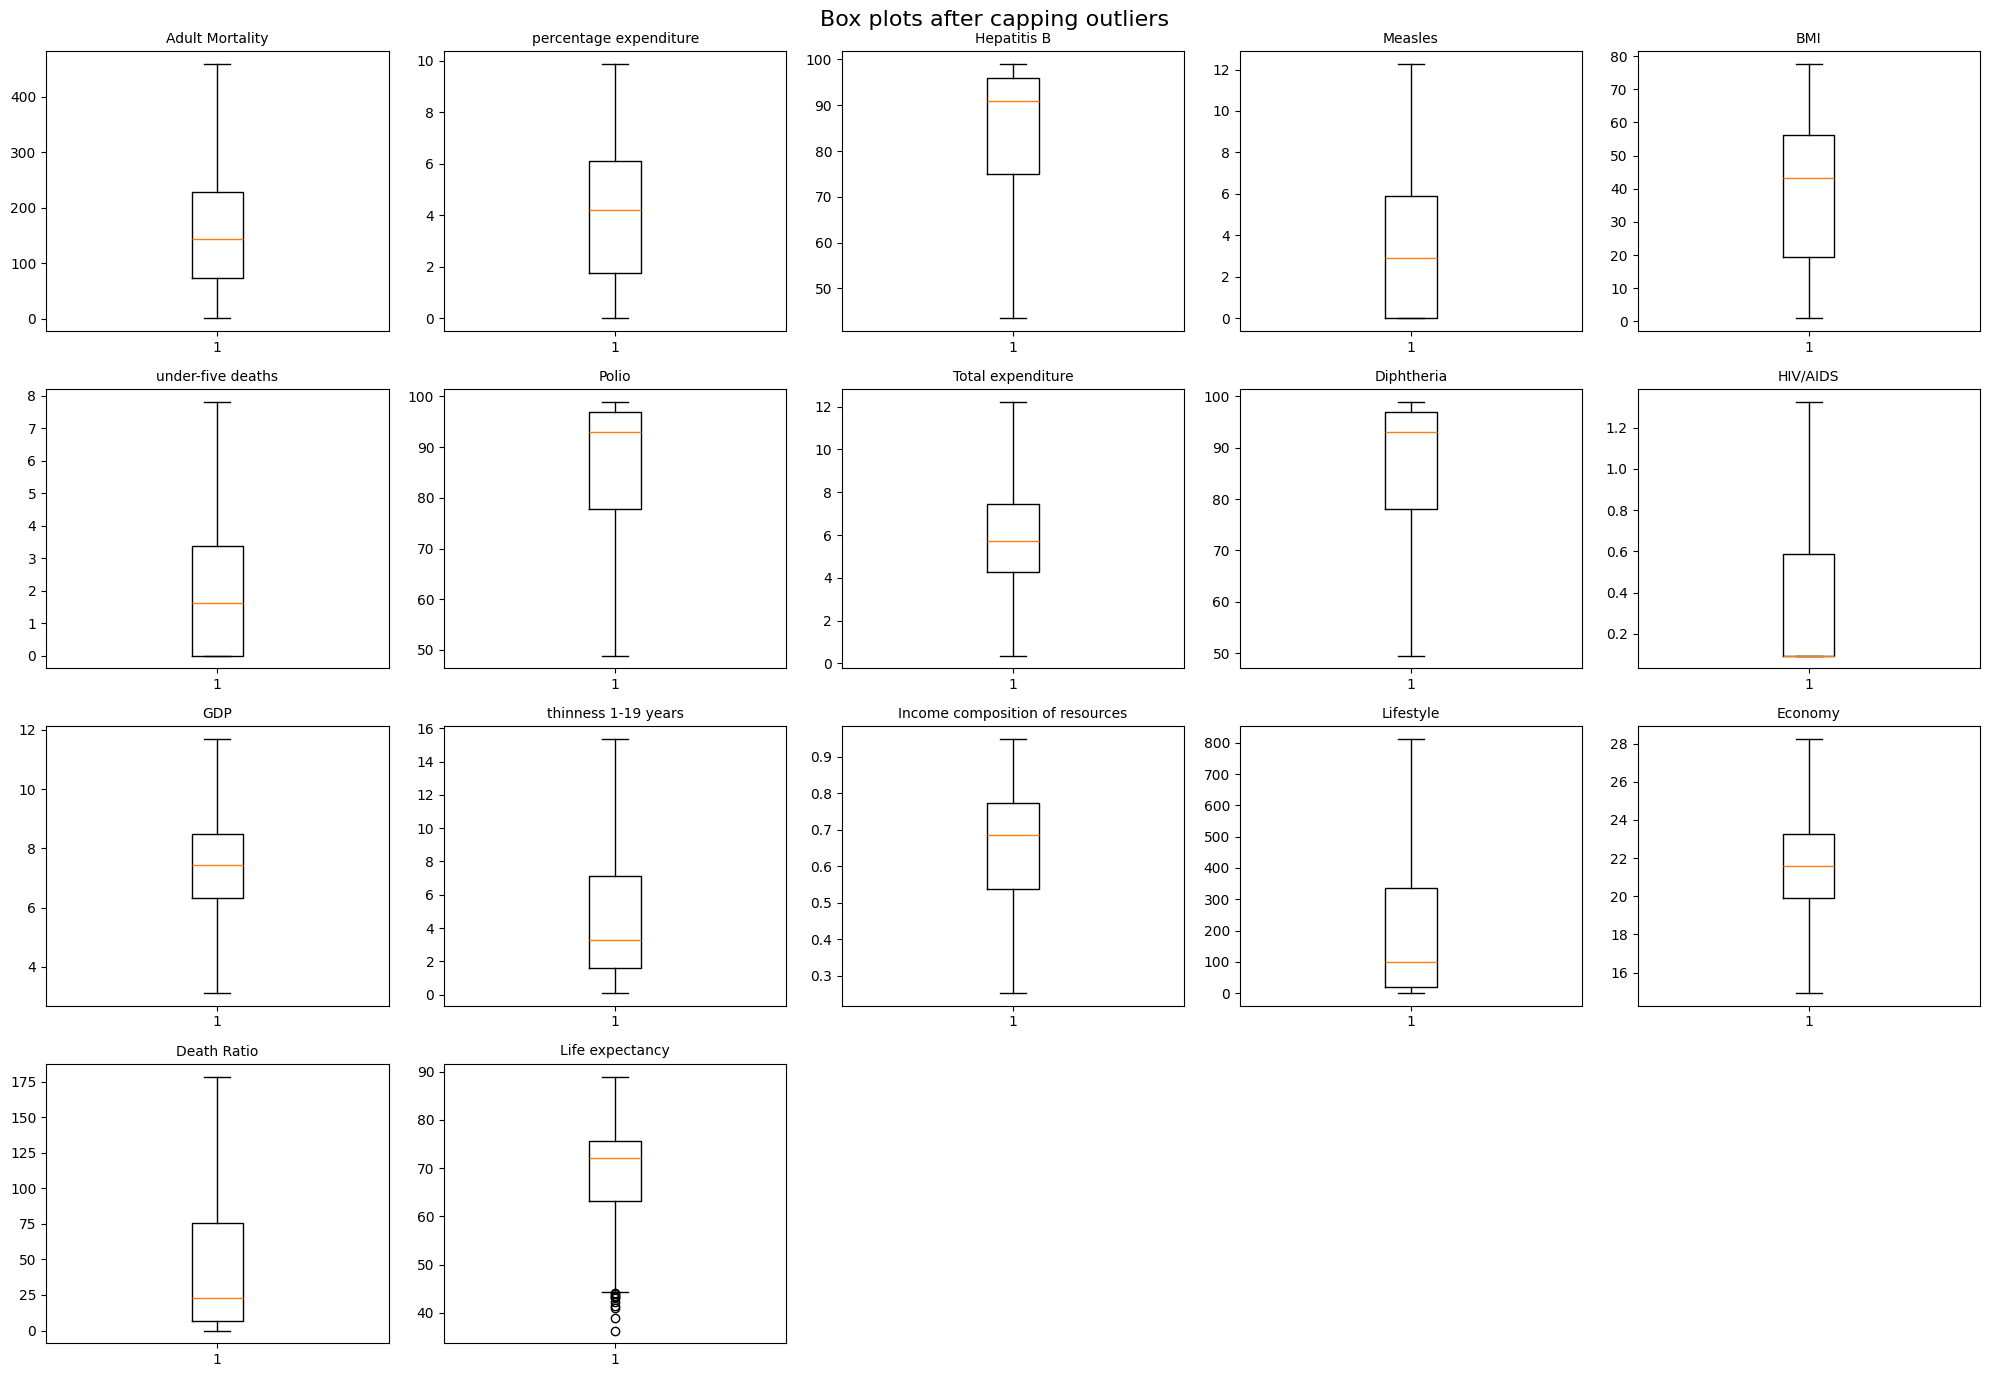

In [17]:
for col in features:
    df[col] = df[col].clip(lower[col], upper[col])

fig, axes = plt.subplots(4, 5, figsize=(20, 14))
axes = axes.flatten()
for i, col in enumerate(features + [target]):
    axes[i].boxplot(df[col])
    axes[i].set_title(col, fontsize=10)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.suptitle('Box plots after capping outliers', fontsize=16)
plt.tight_layout()
plt.show()

## Task 5: Data analysis questions

### Q1. Should a country with low life expectancy (< 65) increase its healthcare expenditure?

In [18]:
low = df[df[target] < 65]
high = df[df[target] >= 65]
print('Countries-years with LE < 65:', len(low), '| LE >= 65:', len(high))

print('\nAverage Total expenditure (% of govt spending on health):')
print('  LE < 65 :', round(low['Total expenditure'].mean(), 2))
print('  LE >= 65:', round(high['Total expenditure'].mean(), 2))

print('\nCorrelation with life expectancy inside the LE < 65 group:')
print('  Total expenditure     :', round(low['Total expenditure'].corr(low[target]), 3))
print('  log(% expenditure)    :', round(low['percentage expenditure'].corr(low[target]), 3))

Countries-years with LE < 65: 851 | LE >= 65: 2077

Average Total expenditure (% of govt spending on health):
  LE < 65 : 5.31
  LE >= 65: 6.12

Correlation with life expectancy inside the LE < 65 group:
  Total expenditure     : -0.142
  log(% expenditure)    : -0.014


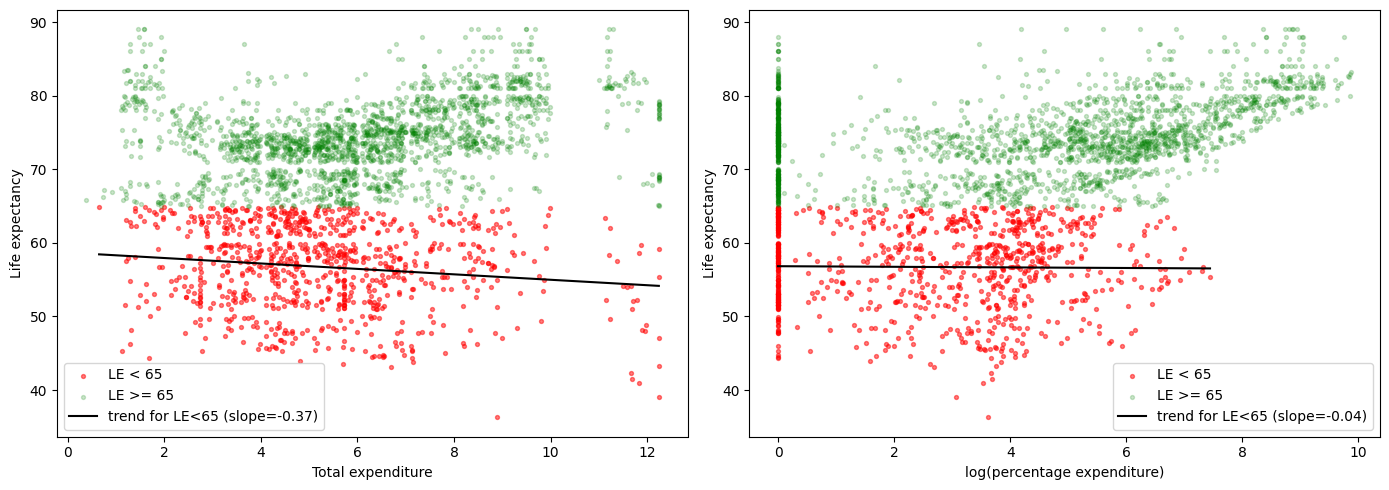

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ['Total expenditure', 'percentage expenditure']):
    ax.scatter(low[col], low[target], s=8, alpha=0.5, label='LE < 65', color='red')
    ax.scatter(high[col], high[target], s=8, alpha=0.2, label='LE >= 65', color='green')
    m, c = np.polyfit(low[col], low[target], 1)
    xs = np.linspace(low[col].min(), low[col].max(), 50)
    ax.plot(xs, m * xs + c, color='black', label=f'trend for LE<65 (slope={m:.2f})')
    ax.set_xlabel(col if col == 'Total expenditure' else 'log(percentage expenditure)')
    ax.set_ylabel(target)
    ax.legend()
plt.tight_layout()
plt.show()

**Answer:** Countries with LE < 65 do spend a bit less on health (about 5.3% vs 6.1%). But **inside this group, health expenditure has basically no relationship with life expectancy** (correlations are close to 0, slightly negative). The trend lines are almost flat. So from this data, just increasing healthcare expenditure would **not** clearly improve lifespan for these countries. Their low life expectancy is driven much more by HIV/AIDS, adult mortality and low income composition (see Task 6 and 7). Spending would need to be targeted at those problems (like HIV treatment and vaccination) to make a difference.

### Q2. What is the impact of schooling on lifespan?

Correlation: 0.75
Each extra year of schooling ≈ +2.32 years of life expectancy


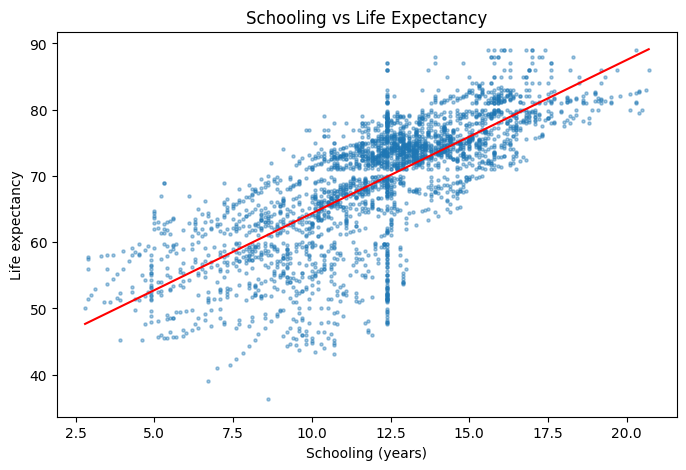

In [20]:
r = df['Schooling'].corr(df[target])
slope, intercept = np.polyfit(df['Schooling'], df[target], 1)
print('Correlation:', round(r, 3))
print(f'Each extra year of schooling ≈ +{slope:.2f} years of life expectancy')

plt.figure(figsize=(8, 5))
plt.scatter(df['Schooling'], df[target], s=5, alpha=0.4)
xs = np.linspace(df['Schooling'].min(), df['Schooling'].max(), 50)
plt.plot(xs, slope * xs + intercept, color='red')
plt.xlabel('Schooling (years)')
plt.ylabel(target)
plt.title('Schooling vs Life Expectancy')
plt.show()

**Answer:** Schooling has a strong **positive** relationship with life expectancy. Countries with more years of schooling live a lot longer (see the slope above). Education probably helps through better health knowledge, better jobs and higher income.

### Q3. Does Life Expectancy have a positive or negative relationship with drinking alcohol?

Correlation Alcohol vs LE: 0.406

Correlation of Alcohol with Developed status / GDP:
  Developed: 0.599
  log(GDP) : 0.407

Average alcohol by status:
Status
Developed     9.86
Developing    3.51
Name: Alcohol, dtype: float64


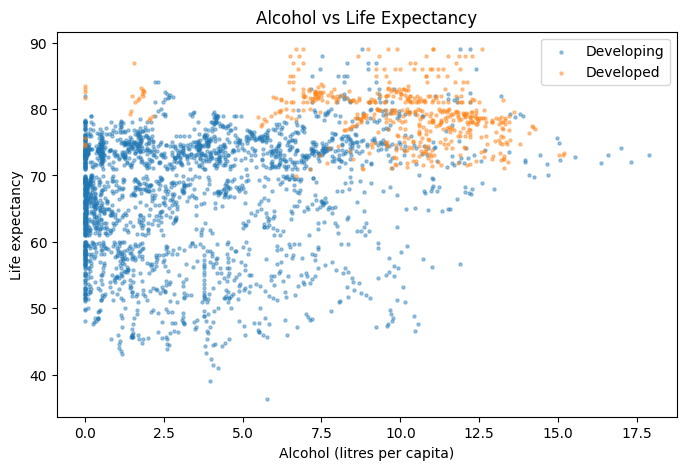

In [21]:
print('Correlation Alcohol vs LE:', round(df['Alcohol'].corr(df[target]), 3))

# check if it is just because rich countries drink more
print('\nCorrelation of Alcohol with Developed status / GDP:')
print('  Developed:', round(df['Alcohol'].corr((df['Status'] == 'Developed').astype(int)), 3))
print('  log(GDP) :', round(df['Alcohol'].corr(df['GDP']), 3))
print('\nAverage alcohol by status:')
print(df.groupby('Status')['Alcohol'].mean().round(2))

plt.figure(figsize=(8, 5))
for s, c in [('Developing', 'tab:blue'), ('Developed', 'tab:orange')]:
    d = df[df['Status'] == s]
    plt.scatter(d['Alcohol'], d[target], s=5, alpha=0.4, label=s, color=c)
plt.xlabel('Alcohol (litres per capita)')
plt.ylabel(target)
plt.legend()
plt.title('Alcohol vs Life Expectancy')
plt.show()

**Answer:** In this data the relationship is **positive**, but I don't think alcohol makes people live longer. Developed (richer) countries drink a lot more and also have better healthcare, so the positive correlation comes from wealth. It's correlation, not causation.

### Q4. Do densely populated countries tend to have lower life expectancy?

                 count   mean  median
Population Size                      
Small              234  71.95   73.15
Medium             176  70.29   71.85
Large             2518  68.90   71.90

Correlation log(Population) vs LE: -0.097


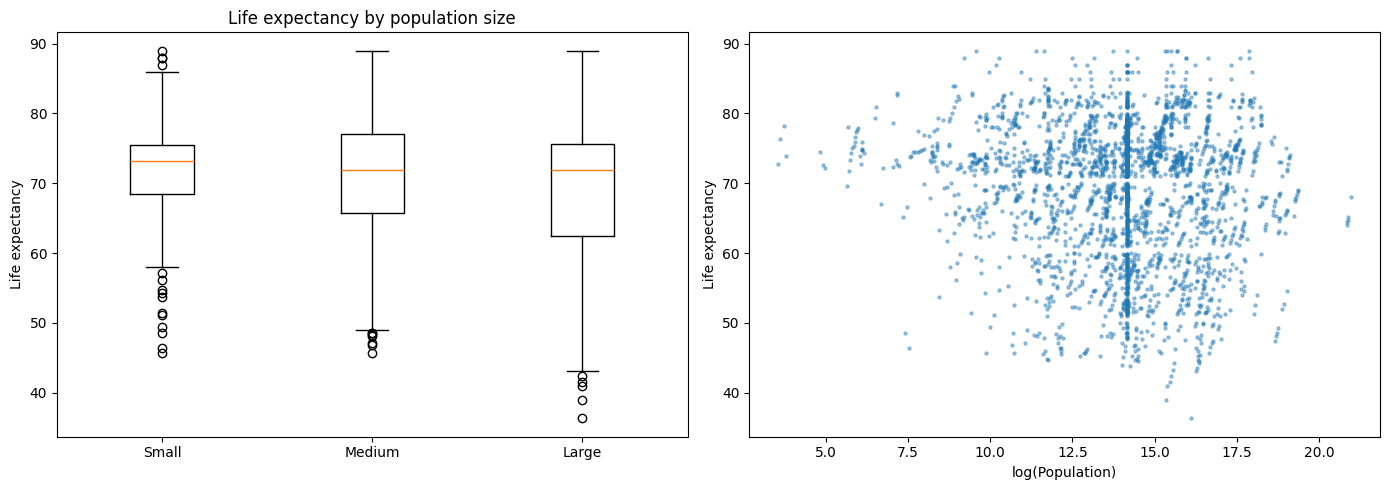

In [22]:
print(df.groupby('Population Size')[target].agg(['count', 'mean', 'median']).round(2))
print('\nCorrelation log(Population) vs LE:', round(df['Population'].corr(df[target]), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
groups = ['Small', 'Medium', 'Large']
axes[0].boxplot([df[df['Population Size'] == g][target] for g in groups], labels=groups)
axes[0].set_ylabel(target)
axes[0].set_title('Life expectancy by population size')
axes[1].scatter(df['Population'], df[target], s=5, alpha=0.4)
axes[1].set_xlabel('log(Population)')
axes[1].set_ylabel(target)
plt.tight_layout()
plt.show()

**Answer:** The dataset has population, not density (there's no land area column), so I use population size. Large countries have a slightly lower average life expectancy (68.9 vs ~72 for small ones), but the medians are almost the same and the correlation is only about -0.1. So there's only a **very weak** tendency, and population size is not an important factor. (The population column is also quite messy in this dataset, some values look like they are missing digits, so I don't trust this result much.)

## Task 6: Linear regression model

In [23]:
X = df[features].copy()
X['Developed'] = (df['Status'] == 'Developed').astype(int)  # convert Status to 0/1
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

Train: (2196, 17)  Test: (732, 17)


LinearRegression()

In [24]:
def evaluate(X_part, y_part, name):
    pred = model.predict(X_part)
    rmse = np.sqrt(mean_squared_error(y_part, pred))
    mape = mean_absolute_percentage_error(y_part, pred) * 100
    r2 = r2_score(y_part, pred)
    return {'Set': name, 'RMSE': round(rmse, 3), 'MAPE (%)': round(mape, 3), 'R2': round(r2, 3)}

results = pd.DataFrame([evaluate(X_train, y_train, 'Train'),
                        evaluate(X_test, y_test, 'Test'),
                        evaluate(X, y, 'Entire data')])
results

,Set,RMSE,MAPE (%),R2
0,Train,3.569,4.037,0.861
1,Test,3.611,4.177,0.853
2,Entire data,3.580,4.072,0.859


In [25]:
coef = pd.Series(model.coef_, index=X.columns).sort_values()
coef

HIV/AIDS                           -6.746503
under-five deaths                  -0.559809
thinness 1-19 years                -0.068564
Measles                            -0.061529
GDP                                -0.052666
Hepatitis B                        -0.016190
Adult Mortality                    -0.013536
Death Ratio                        -0.009640
Lifestyle                          -0.000055
BMI                                 0.000078
Polio                               0.008045
Diphtheria                          0.052963
Total expenditure                   0.074085
percentage expenditure              0.080299
Economy                             0.080433
Developed                           1.309153
Income composition of resources    22.804248
dtype: float64

**Observation:** Train and test scores are very close (R² ≈ 0.86 vs 0.85, RMSE ≈ 3.6 years for both), so the model is not overfitting. The MAPE is about 4%, so on average the prediction is off by around 4%. Income composition and HIV/AIDS have the biggest coefficients.

### Residual scatter plot
Actual value on the x-axis and predicted value on the y-axis. The red line is a perfect prediction. The dashed lines are my **error lines at ±10%** of the actual value (I chose 10% because the MAPE is a few percent, so 10% is a reasonable acceptable error).

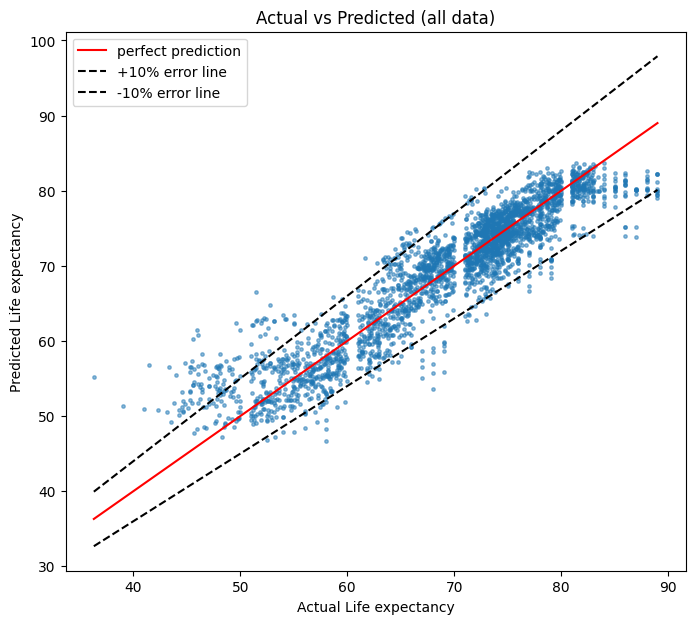

Points inside the ±10% lines: 2676 / 2928 (91.39%)


In [26]:
y_pred_all = model.predict(X)

def residual_plot(actual, predicted, title):
    plt.figure(figsize=(8, 7))
    plt.scatter(actual, predicted, s=6, alpha=0.5)
    xs = np.linspace(actual.min(), actual.max(), 100)
    plt.plot(xs, xs, color='red', label='perfect prediction')
    plt.plot(xs, xs * 1.10, 'k--', label='+10% error line')
    plt.plot(xs, xs * 0.90, 'k--', label='-10% error line')
    plt.xlabel('Actual Life expectancy')
    plt.ylabel('Predicted Life expectancy')
    plt.title(title)
    plt.legend()
    plt.show()

residual_plot(y, y_pred_all, 'Actual vs Predicted (all data)')

inside = (np.abs(y_pred_all - y) / y <= 0.10)
print(f'Points inside the ±10% lines: {inside.sum()} / {len(y)} ({inside.mean()*100:.2f}%)')

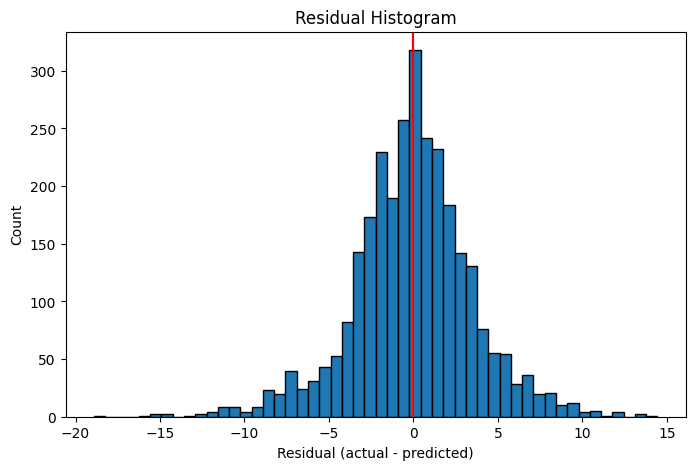

Mean residual: -0.0595


In [27]:
residuals = y - y_pred_all
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50, edgecolor='black')
plt.axvline(0, color='red')
plt.xlabel('Residual (actual - predicted)')
plt.ylabel('Count')
plt.title('Residual Histogram')
plt.show()
print('Mean residual:', round(residuals.mean(), 4))

**Observation:** The residuals are roughly bell shaped around 0, which is what we want for linear regression. There are a few big residuals, mostly countries that had a sudden drop or wrong value in life expectancy (for example Haiti 2010 with the earthquake).

## Task 7: Minimum number of features

I want the smallest set of features that still keeps the data inside the ±10% error lines as well as the full model does.

**My approach (forward selection):** start with no features. In each round, try adding every remaining feature and keep the one that gives the lowest test RMSE. After each round I record how many points fall inside the ±10% lines.

In [28]:
all_feats = list(X.columns)
selected = []
history = []

while len(selected) < len(all_feats):
    best_feat, best_rmse = None, np.inf
    for f in all_feats:
        if f in selected:
            continue
        cols = selected + [f]
        m = LinearRegression().fit(X_train[cols], y_train)
        rmse = np.sqrt(mean_squared_error(y_test, m.predict(X_test[cols])))
        if rmse < best_rmse:
            best_feat, best_rmse = f, rmse
    selected.append(best_feat)

    m = LinearRegression().fit(X_train[selected], y_train)
    p = m.predict(X[selected])
    pct_inside = (np.abs(p - y) / y <= 0.10).mean() * 100
    history.append({'n_features': len(selected), 'added': best_feat,
                    'test RMSE': round(best_rmse, 3),
                    'R2 (all)': round(r2_score(y, p), 3),
                    '% inside ±10%': round(pct_inside, 2)})

history = pd.DataFrame(history)
history

,n_features,added,test RMSE,R2 (all),% inside ±10%
0,1,Income composition of resources,5.165,0.717,85.59
1,2,HIV/AIDS,4.140,0.817,89.00
2,3,Adult Mortality,3.871,0.842,90.64
3,4,Diphtheria,3.757,0.848,91.33
4,5,under-five deaths,3.688,0.852,91.43
5,6,Developed,3.635,0.855,91.26
6,7,Total expenditure,3.610,0.856,91.70
7,8,Economy,3.592,0.857,91.94
8,9,percentage expenditure,3.588,0.857,91.91
9,10,Polio,3.586,0.857,91.94


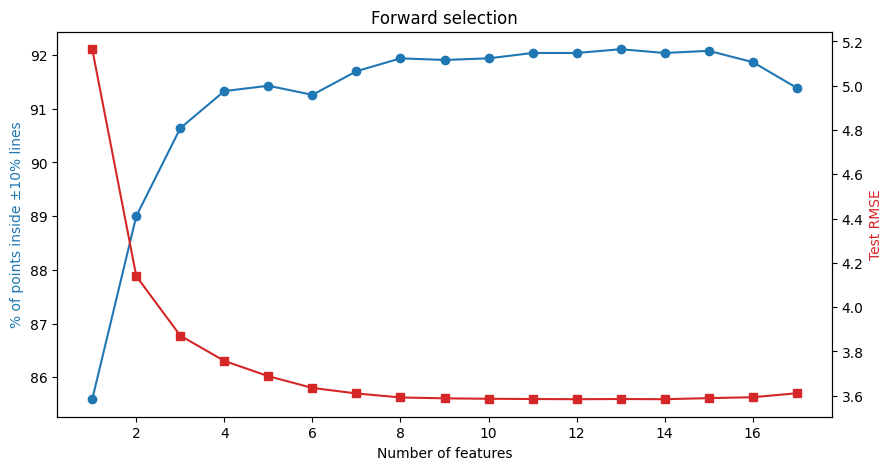

In [29]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(history['n_features'], history['% inside ±10%'], marker='o', color='tab:blue')
ax1.set_xlabel('Number of features')
ax1.set_ylabel('% of points inside ±10% lines', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(history['n_features'], history['test RMSE'], marker='s', color='tab:red')
ax2.set_ylabel('Test RMSE', color='tab:red')
plt.title('Forward selection')
plt.show()

Full model coverage: 91.39 %
Minimum number of features: 4
Features: ['Income composition of resources', 'HIV/AIDS', 'Adult Mortality', 'Diphtheria']

R2 (all data): 0.848 | RMSE: 3.71


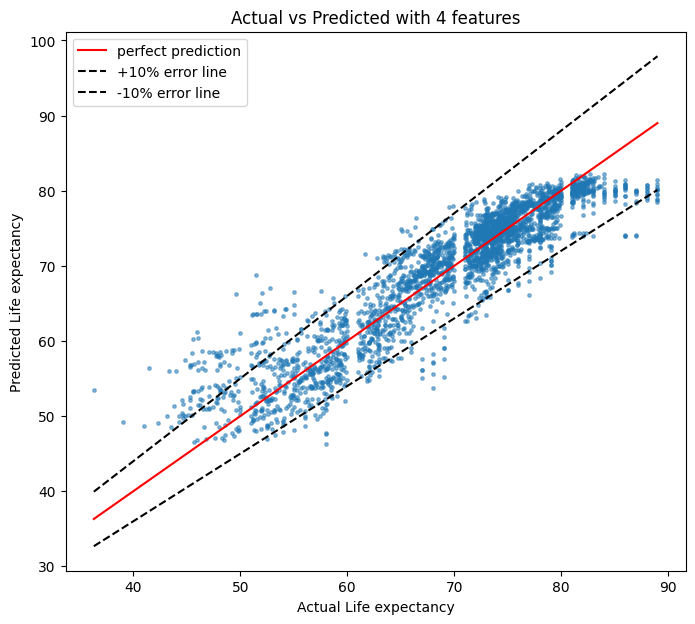

Points still outside the error lines:


,Country,Year,Life expectancy,Predicted
13,Afghanistan,2002,56.2,62.7
50,Angola,2013,51.1,56.6
53,Angola,2010,49.6,55.0
55,Angola,2008,48.7,53.7
56,Angola,2007,48.2,53.5
...,...,...,...,...
2933,Zimbabwe,2004,44.3,50.0
2934,Zimbabwe,2003,44.5,50.5
2935,Zimbabwe,2002,44.8,57.4
2936,Zimbabwe,2001,45.3,51.1


In [30]:
# smallest number of features that reaches (almost) the same coverage as the full model
full_cov = history['% inside ±10%'].iloc[-1]
min_n = history[history['% inside ±10%'] >= full_cov - 0.25]['n_features'].min()
min_feats = selected[:min_n]
print('Full model coverage:', full_cov, '%')
print('Minimum number of features:', min_n)
print('Features:', min_feats)

m_small = LinearRegression().fit(X_train[min_feats], y_train)
p_small = m_small.predict(X[min_feats])
print('\nR2 (all data):', round(r2_score(y, p_small), 3),
      '| RMSE:', round(np.sqrt(mean_squared_error(y, p_small)), 3))
residual_plot(y, p_small, f'Actual vs Predicted with {min_n} features')

outside = df.loc[np.abs(p_small - y) / y > 0.10, ['Country', 'Year', target]]
outside['Predicted'] = p_small[np.abs(p_small - y) / y > 0.10].round(1)
print('Points still outside the error lines:')
outside

## Conclusion

- The linear regression model gets **R² ≈ 0.86** and **RMSE ≈ 3.6 years** on both train and test sets.
- **Minimum features (Task 7): 4 – Income composition of resources, HIV/AIDS, Adult Mortality and Diphtheria.** With just these 4 the model already gets R² ≈ 0.85 and the same share of points inside the ±10% lines as the full 17-feature model (~91%). Adding more features barely changes anything.
- No combination of features gets **all** points inside the ±10% lines; the best is about 92%. Most of the points outside are African countries in the early 2000s with very high HIV (like Zimbabwe, Angola), where the model predicts too high. Part of the reason is that I capped HIV/AIDS outliers in Task 4, so the model can't see how extreme those values were. The rest are odd values in the data (like Haiti 2010 or sudden jumps in life expectancy).
- **Answers:** more health expenditure alone doesn't clearly help low-LE countries, schooling has a strong positive effect (~+2.3 years per extra year of school), alcohol has a positive correlation only because richer countries drink more, and population size has almost no effect.